# Week 5: Support Vector Machines, the Kernel Trick, and Regularization
**Rupal Paliwal, Mod C, Semester 1**

**Dataset:** Movies Box Office 2000 to 2024 (Kaggle), the same 5,000 films used in earlier weeks.

**Question:** Same classification task as Week 4: is a film a **hit** (worldwide gross above the median of all 5,000 films)? Can a support vector machine (SVM) beat logistic regression's 78.3% test accuracy, and does a curved (kernel) boundary help?

**Part 1** uses the box office data. **Part 2** adds the other two project datasets, MovieLens 20M and the 4 Services Streaming catalogs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

## 1. Load and prepare the data

Same preparation as Weeks 2 and 4: rating converted from text like `'8.217/10'`, vote count logged, genres as 0/1 columns, the top 10 languages as 0/1 columns (English is the reference), and rows with missing or zero ratings dropped. The money columns other than the target are left out because worldwide gross is domestic plus foreign, so they would leak the answer.

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')

data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

# Numeric features
X = pd.DataFrame({
    'log_votes': np.log1p(data['Vote_Count']),
    'rating': data['Rating_num'],
    'year': data['Year'],
}, index=data.index)

# Genres (multi hot) and top 10 languages (English is the reference)
genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')
top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)

X = pd.concat([X, genres, langs], axis=1)
threshold = df['$Worldwide'].median()
y = (data['$Worldwide'] > threshold).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Hit threshold: $', round(threshold), '| Share of hits:', round(y.mean(), 3))
print('Train:', X_train.shape, '| Test:', X_test.shape)

Hit threshold: $ 48446575 | Share of hits: 0.51
Train: (3842, 32) | Test: (961, 32)


## 2. Three kernels with default settings

Every model standardizes the features first. SVMs are distance based, so this is essential (Week 4 showed what happens to unscaled features). I compare a **linear** kernel (a flat boundary), a **polynomial** kernel (degree 3), and a **Gaussian (RBF)** kernel, all with the default C = 1.

In [3]:
rows = []
for kernel in ['linear', 'poly', 'rbf']:
    m = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1)).fit(X_train, y_train)
    rows.append({'kernel': kernel,
                 'train_accuracy': round(accuracy_score(y_train, m.predict(X_train)), 4),
                 'test_accuracy': round(accuracy_score(y_test, m.predict(X_test)), 4),
                 'support_vectors': m[-1].n_support_.sum()})
pd.DataFrame(rows)

,kernel,train_accuracy,test_accuracy,support_vectors
0,linear,0.7933,0.7836,1933
1,poly,0.7884,0.7159,2485
2,rbf,0.8274,0.7752,2149


About half of the 3,842 training films end up as support vectors. That tells me the two classes overlap heavily: there is no clean gap between hits and non hits, so many films sit on or inside the margin.

## 3. Regularization: the C parameter

C controls the trade off from the lesson. A **small C** prefers a wide margin and tolerates misclassified training films. A **large C** tries hard to classify every training film correctly, even if the margin becomes narrow and twisty. I sweep C for the RBF kernel and watch training vs. test accuracy.

In [4]:
Cs = [0.01, 0.1, 1, 10, 100, 1000]
sweep = []
for C in Cs:
    m = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=C)).fit(X_train, y_train)
    sweep.append({'C': C,
                  'train_accuracy': accuracy_score(y_train, m.predict(X_train)),
                  'test_accuracy': accuracy_score(y_test, m.predict(X_test)),
                  'support_vectors': m[-1].n_support_.sum()})
sweep = pd.DataFrame(sweep)
sweep.round(4)

,C,train_accuracy,test_accuracy,support_vectors
0,0.01,0.7012,0.6795,3687
1,0.10,0.7670,0.7378,2617
2,1.00,0.8274,0.7752,2149
3,10.00,0.8719,0.7669,1947
4,100.00,0.9047,0.7461,1798
5,1000.00,0.9287,0.7492,1622


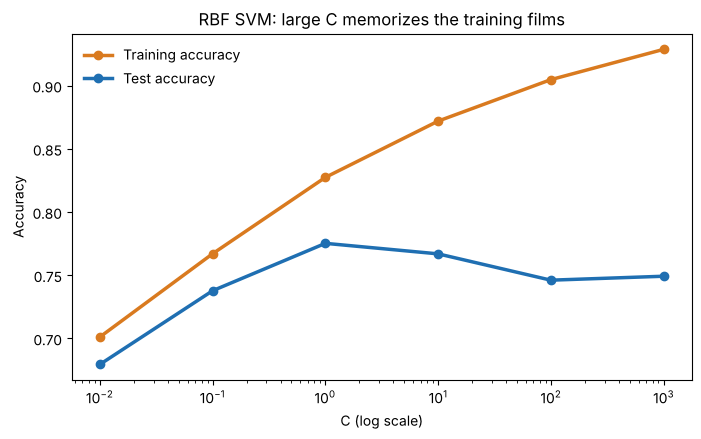

In [5]:
plt.figure(figsize=(8, 4.5))
plt.plot(sweep['C'], sweep['train_accuracy'], color='#d97a1f', linewidth=2.5, marker='o', label='Training accuracy')
plt.plot(sweep['C'], sweep['test_accuracy'], color='#1f6fb2', linewidth=2.5, marker='o', label='Test accuracy')
plt.xscale('log')
plt.xlabel('C (log scale)')
plt.ylabel('Accuracy')
plt.title('RBF SVM: large C memorizes the training films')
plt.legend(frameon=False)
plt.show()

At C = 0.01 the model underfits (both accuracies low). Test accuracy peaks around C = 1. Beyond that, training accuracy keeps climbing to 93% while test accuracy falls, which is overfitting: the boundary bends around individual training films.

## 4. Hyperparameter tuning with cross validation

I tune the kernel and its settings together with a grid search and 5 fold stratified CV on the training set only:
- **C**: margin width vs. training errors (all kernels)
- **gamma** (RBF only): how far one film's influence reaches. Large gamma means very local, wiggly boundaries.
- **degree** (polynomial only): how curved the boundary can be

In [6]:
grid = [
    {'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1, 10]},
    {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.003, 0.01, 0.03, 0.1]},
    {'svc__kernel': ['poly'], 'svc__C': [0.1, 1, 10], 'svc__degree': [2, 3]},
]
search = GridSearchCV(make_pipeline(StandardScaler(), SVC()), grid, cv=skf, n_jobs=-1)
search.fit(X_train, y_train)

print('Best settings:', search.best_params_)
print('Best CV accuracy:', round(search.best_score_, 4))
print('Test accuracy:', round(accuracy_score(y_test, search.predict(X_test)), 4))

Best settings: {'svc__C': 1, 'svc__kernel': 'linear'}
Best CV accuracy: 0.7884
Test accuracy: 0.7836


In [7]:
res = pd.DataFrame(search.cv_results_)
res['kernel'] = res['param_svc__kernel']
res.groupby('kernel')['mean_test_score'].max().round(4).rename('best CV accuracy')

kernel
linear    0.7884
poly      0.7673
rbf       0.7881
Name: best CV accuracy, dtype: float64

In [8]:
pd.DataFrame(confusion_matrix(y_test, search.predict(X_test)),
             index=['Actual: not a hit', 'Actual: hit'],
             columns=['Predicted: not a hit', 'Predicted: hit'])

,Predicted: not a hit,Predicted: hit
Actual: not a hit,352,119
Actual: hit,89,401


## 5. Seeing the kernel trick

With all 32 features the boundary can't be drawn, so I refit linear and RBF SVMs on just two features (log votes and rating) to see what the kernel changes. Dots are a sample of training films.

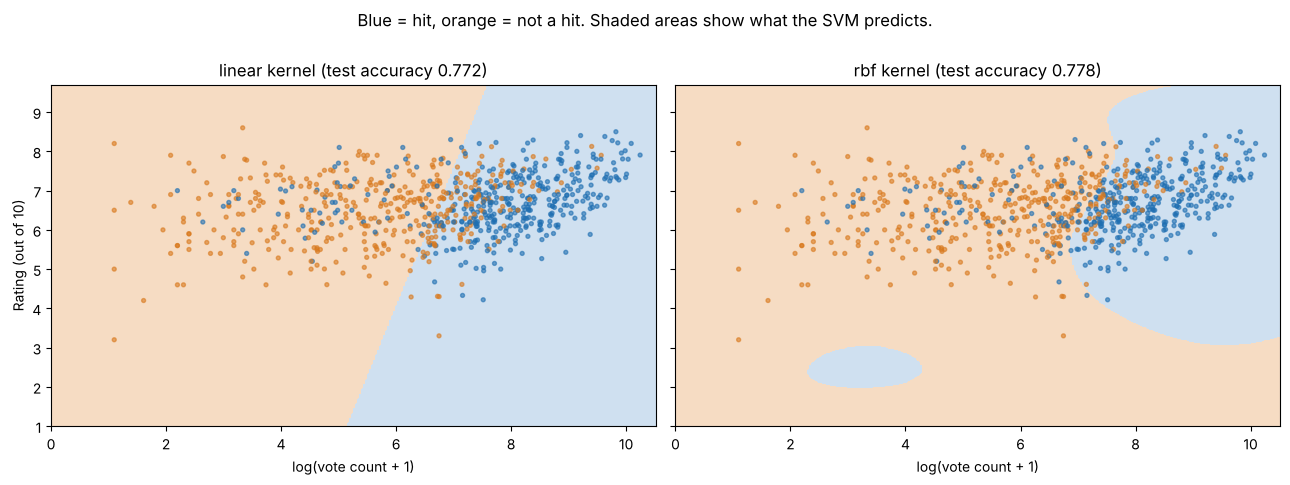

In [9]:
two = ['log_votes', 'rating']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
xx, yy = np.meshgrid(np.linspace(X_train['log_votes'].min(), X_train['log_votes'].max(), 300),
                     np.linspace(X_train['rating'].min(), X_train['rating'].max(), 300))
grid_pts = pd.DataFrame({'log_votes': xx.ravel(), 'rating': yy.ravel()})
sample = X_train.sample(800, random_state=1)

for ax, kernel in zip(axes, ['linear', 'rbf']):
    m = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1)).fit(X_train[two], y_train)
    zz = m.predict(grid_pts).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#f6dcc3', '#cfe0f0'])
    ax.scatter(sample['log_votes'], sample['rating'], c=np.where(y_train[sample.index] == 1, '#1f6fb2', '#d97a1f'),
               s=8, alpha=0.6)
    acc = accuracy_score(y_test, m.predict(X_test[two]))
    ax.set_title(f'{kernel} kernel (test accuracy {acc:.3f})')
    ax.set_xlabel('log(vote count + 1)')
axes[0].set_ylabel('Rating (out of 10)')
fig.suptitle('Blue = hit, orange = not a hit. Shaded areas show what the SVM predicts.', y=1.0)
plt.tight_layout()
plt.show()

The linear boundary is mostly a vote count cutoff, tilted so that a higher rated film needs *more* votes to be predicted a hit. That matches the negative rating effect found in Weeks 2 and 4. The RBF kernel curves the boundary and even invents a small "hit" island at low votes and low ratings, where there are almost no films. That island is the kernel fitting structure that isn't supported by data, and the curved model gains less than one point of accuracy.

# Part 2: All Three Project Datasets

My project has three datasets: the box office data used above, **MovieLens 20M** (user ratings, tags, and the tag genome), and the **4 Services Streaming** catalogs (Netflix, Prime Video, Hulu, Disney+). `OMDS-ModC-DataPrep-Paliwal-Rupal.ipynb` joins them by cleaned title and release year and saves `combined_films.csv`.

MovieLens 20M ends in 2015, so Part 2 uses the **films released 2000 to 2015 that matched MovieLens**. To see what the extra datasets add, every model is fit twice on exactly the same films and split:
- **Box office only**: the same 32 features as Part 1
- **All three datasets**: those 32 plus 7 new ones: MovieLens rating count (log), MovieLens average rating, MovieLens tag count (log), and 0/1 flags for Netflix, Prime Video, Hulu, and Disney+

In [10]:
combo = pd.read_csv('combined_films.csv')     # same row order as the box office file
sub = combo.loc[X.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0)]

extra = pd.DataFrame({
    'ml_log_ratings': np.log1p(sub['ml_n_ratings']),   # MovieLens: how many users rated the film
    'ml_mean_rating': sub['ml_mean_rating'],            # MovieLens: average user rating (0.5 to 5 stars)
    'ml_log_tags': np.log1p(sub['ml_n_tags']),          # MovieLens: how many tags users added
    'on_netflix': sub['on_netflix'], 'on_prime': sub['on_prime'],
    'on_hulu': sub['on_hulu'], 'on_disney': sub['on_disney'],   # streaming catalogs
}, index=sub.index)

XA = X.loc[sub.index]               # box office only
XB = pd.concat([XA, extra], axis=1)      # all three datasets
y3 = (sub['$Worldwide'] > df['$Worldwide'].median()).astype(int)   # hit = above the median of all 5,000 films
print('Films in Part 2:', len(sub), '| years', sub['Year'].min(), 'to', sub['Year'].max())
print('Box office features:', XA.shape[1], '| all three datasets:', XB.shape[1])

Films in Part 2: 2407 | years 2000 to 2015
Box office features: 32 | all three datasets: 39


## P2.1 SVM with all three datasets

Same grid search as above (linear and RBF kernels, C and gamma tuned by stratified 5 fold CV) on the 2000 to 2015 films, with and without the extra features.

In [11]:
tr3, te3 = train_test_split(XA.index, test_size=0.2, random_state=42, stratify=y3)
grid3 = [{'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1, 10]},
         {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.01, 0.03]}]
rows = []
for name, Z in [('Box office only', XA), ('All three datasets', XB)]:
    s = GridSearchCV(make_pipeline(StandardScaler(), SVC()), grid3, cv=skf, n_jobs=-1).fit(Z.loc[tr3], y3[tr3])
    rows.append({'features': name, 'best_kernel': s.best_params_['svc__kernel'], 'best_C': s.best_params_['svc__C'],
                 'CV_accuracy': round(s.best_score_, 4), 'test_accuracy': round(accuracy_score(y3[te3], s.predict(Z.loc[te3])), 4)})
print('Share of hits in this subset:', round(y3.mean(), 3))
pd.DataFrame(rows)

Share of hits in this subset: 0.595


,features,best_kernel,best_C,CV_accuracy,test_accuracy
0,Box office only,linear,0.1,0.8068,0.8029
1,All three datasets,linear,1.0,0.8145,0.8195


## 6. Conclusions

**The best SVM is a linear one, and it ties logistic regression.** After tuning, the best model is a linear kernel with C = 1: CV accuracy 0.788 and **test accuracy 0.784**, compared with 0.783 for logistic regression in Week 4. The confusion matrix is almost identical too (119 false hits, 89 missed hits). The tuned RBF kernel scored the same in CV (0.788) and the polynomial kernel was worse (0.767).

**The kernel trick didn't help here, which surprised me.** Week 1 showed that revenue is a curved function of votes, so I expected a curved boundary to win. But for a yes/no "above the median" question, all that matters is *where* the cutoff falls, and that cutoff is close to a straight line in log votes. Curvature that matters for predicting the exact revenue doesn't matter for this classification.

**Regularization (C) controlled overfitting.** Small C (0.01) underfit, with 68% test accuracy. Large C (1,000) overfit: 93% training accuracy but only 75% on the test set. CV picked C = 1. About half the training films were support vectors, which tells me hits and non hits overlap heavily, so some error is unavoidable with these features.

**How I avoided overfitting:** standardized features, C and gamma chosen by 5 fold stratified CV on the training set only, and one final check on the untouched test set. Train and test accuracy for the chosen model are within 1 point (0.793 vs. 0.784).

**Part 2 (all three datasets).** With the MovieLens and streaming features, the tuned SVM gains a little under 2 points of test accuracy on the 2000 to 2015 films, and the linear kernel is still chosen over RBF. The extra audience features shift the boundary but do not make it curved.

### Think About It

- **Can we be sure the margin on one side equals the margin on the other?** Yes. If one side's margin were larger, we could slide the hyperplane toward that side. That makes the smaller margin bigger, so the overall margin improves. The best (maximum margin) hyperplane therefore always sits exactly halfway, with equal margins on both sides.
- **Polynomial kernel for 2 dimensional vectors, K(x, z) = (x · z)².** Expanding gives (x₁z₁ + x₂z₂)² = x₁²z₁² + 2x₁x₂z₁z₂ + x₂²z₂². This equals the inner product of φ(x) = (x₁², √2·x₁x₂, x₂²) with φ(z). Written like the lesson's vector, it is also the inner product of (x₁x₁, x₁x₂, x₂x₁, x₂x₂) with the same vector for z.
- **How can we tell the Gaussian kernel is not simply the inner product of x with z?** K(x, x) = exp(0) = 1 for every x, but x · x = |x|² changes with x. Also, an inner product doubles when x doubles, and the Gaussian kernel doesn't. It *is* an inner product of some vectors, but those vectors live in an infinite dimensional space (from the Taylor series of exp), so they are not easy to write down.
- **Why does maximizing the margin help with new data?** A wide margin means every training film is far from the boundary. A new film similar to the training films is then likely to land on the correct side too, instead of being flipped by a small difference.
- **How does a kernel help separate data that can't be split with a straight line?** It implicitly maps the films into a higher dimensional space where a flat hyperplane can separate them. Back in the original space, that flat hyperplane becomes a curved boundary, like the RBF panel above.
- **When is it better to allow some misclassified points for a larger margin, and how does C manage that?** When a few points are noise or outliers, forcing them onto the right side gives a narrow, fragile boundary. A smaller C allows those mistakes in exchange for a wider margin. In my sweep, C = 1 accepted 17% training errors and gave the best test accuracy, while C = 1,000 cut training errors to 7% but did worse on new films.